# Case Study Imaging Analysis
In this tutorial, we are going to analyse some data acquired using intrinsic optical imaging and using two\-photon imaging.

## Refresher
Let's begin with a refresher on 3D matrices and functions, as we will use them extensively in this practical.

### 3D matrices
We can create three-dimensional matrices by 'stacking' two two-dimensional matrices along a new, third dimension:

```python
c = np.stack(a, b, axis=2)
```

Note that `a` and `b` must have compatible sizes for this to work, i.e., they must have the same size.

In [ ]:
# Import the necessary packages
import numpy as np

# Create two 2D matrices a and b
a = np.array(
    [[3, 5, 8, 10, 8],
     [7, 10, 3, 5, 3],
     [7, 3, 5, 1, 8],
     [2, 6, 7, 1, 2],
     [1, 2, 9, 3, 9]]
)

b = np.array(
    [[3, 4, 3, 1, 1],
     [2, 8, 8, 1, 6],
     [3, 6, 8, 5, 5],
     [6, 5, 4, 8, 0],
     [5, 9, 6, 9, 3]]
)

# Stack a and b to create a new 3D matrix
c = np.stack((a, b), axis=2)
print(f"Shape of c: {c.shape}")

Another nice feature of NumPy is that many functions can operate along certain dimensions or axes of an array. Let's suppose we have a matrix with three dimensions: (trials, stimulus repetitions, time). If we want to find the average responses to stimulus repetitions in time but over trials, we want to average over the trial dimension. This can be done by supplying the dimension we want to average over as an argument to the function of interest:

```python
trial_mean = np.mean(data, axis=0)
```

The keyword-argument pair `axis=0` indicates that we want to take the mean over the first dimension, i.e., the trial dimension. We can also take the mean over multiple dimensions at the same time by providing a tuple of axes, e.g.,

```python
trial_reps_mean = np.mean(data, axis=(1, 2))
```

Note that some functions accept tuples of axes over which to perform the operation, but not all do. It's always a good idea to check the documentation of a function to see what the supported options are.

In [ ]:
print("Mean of c along the third dimension:")
print(np.mean(c, axis=2))

### Functions
Functions are a nice way to "compartmentalise" a certain piece of code. Especially if you have code that should be rather general to handle different data, it makes sense to define a function that does the operations you want. You can then call this function with different inputs.

A function may take inputs and may supply outputs, but this does not have to be the case. The general form of a function is:

In [ ]:
def do_calculations(input_var1, input_var2):
    """
    Multiplies and divides the input variables

    Args:
        input_var1 (float): The first input variable
        input_var2 (float): The second input variable

    Returns:
        output_var1 (float): The multiplication of input_var1 and input_var2
        output_var2 (float): The division of input_var1 and input_var2
    """
    
    output_var1 = input_var1 * input_var2
    output_var2 = input_var1 / input_var2
    return output_var1, output_var2

The name of this function is `do_calculations`, it takes two input variables `input_var1` and `input_var2`, and it returns two output variables `output_var1` and `output_var2`. These output variables are assigned within the function: In this case, we assign them as the multiplication and division of the input variables, respectively. Note that we explicitly have to return these variables in order to give the function some output.

Note that all variables within a function will not appear in your *global workspace*, but they remain confined to the function. If you want to pass a variable to your global workspace, you need to specify it as an output of the function. Then, you can call the function and assign the result to a new variable, like so:

In [ ]:
mult_div = do_calculations(3, 5)
print(mult_div)

mult, div = do_calculations(3, 5)
print(mult)
print(div)

mult, _ = do_calculations(3, 5)
_, div = do_calculations(3, 5)

We can see multiple ways of assigning the output variables of the function to variables in our global workspace. If we are interested in the entire output of a function, we could assign this into one variable `mult_div`. As our function had multiple outputs, these variables are placed into a tuple, and then assigned to our new single variable.

Alternatively, all output variables can be assigned to their own separate, new variables, e.g., for `mult` and `div`. Assignment will always happen in the order that you specified the output variables after the `return` keyword in the original function. Be mindful of the order and number of returned variables.

If you are only interested in some variables, you can omit assignment of the other output variables by providing an underscore (`_`), as we did in the last two calls to `do_calculations()`.

## Intrinsic optical signal imaging (IOSI)

In (animal) neuroscientific experiments, we often need to decide beforehand where we want to implant an electrode, inject a virus, etc. Besides using a brain atlas to find the correct location, we also use **intrinsic optical imaging** to be able to record a proxy of neural activity non\-invasively. We can do this by measuring changes in **haemodynamics** (blood flow, mainly), akin to fMRI or fNIRS in humans.


In areas where neurons are active, first there is a more deoxygenated haemoglobin (as neuron activity requires more oxygen), followed by an increase in blood flow (to support the increased metabolism) and thus an increase in oxygenated haemoglobin.


To perform the actual imaging, we shine a long\-wavelength red light onto the brain. This light travels through the brain and gets reflected in different amounts depending on the tissue. More importantly, the amount that gets reflected back is different for oxyhaemoglobin and for deoxyhaemoglobin, allowing us to map where there is an increased blood flow and thus increased neuronal activity.


Although this gives us a very coarse location of where neural activity is occurring, this is often precise enough to inform us about where to implant an electrode or where to inject a virus.

#### Retinotopic map

To demonstrate the type of data we can get from IOSI, we will use recordings over visual cortex during a retinotopic mapping experiment. The concept of a **retinotopic map** refers to the fact that the representation of the visual field by retinal neurons carries over to the representation of the visual field in primary visual cortex (V1). This means that adjacent parts of the visual scene on the retina will map to adjacent parts of visual cortex. It is important to note that the centre gaze or the fovea is over\-represented in cortex compared to the periphery, as the ratio of retinal ganglion cells to photoreceptors is higher in the fovea.

#### Case study

In this study, we will investigate data obtained using IOSI from an experiment that aims to find this retinotopic map. An anaesthetised mouse was shown visual stimuli that could appear on the left, in the centre, or on the right of the screen. There are 7 trials for each condition (left, centre, right). This way we can see to what part of the visual field a given part of V1 is responsive to.


Let's load the data first (you can get the data file <samp>IOSI.npy</samp> from Canvas).


In [ ]:
import os
import numpy as np
import matplotlib.pyplot as plt

def ensure_dict(obj):
    """
    Convert a NumPy array loaded with allow_pickle=True into
    a dictionary if possible; otherwise return the object unchanged.
    """
    if isinstance(obj, np.ndarray) and obj.dtype == object and obj.size == 1:
        try:
            return obj.item()   # Extract stored dict
        except Exception:
            pass
    return obj


# Enter the folder in which the data is stored
data_folder = r"C:\Users\brouw\Documents\PhD\Teaching\PAND\Non_git_folder\Imaging_Analysis"
ios = np.load(os.path.join(data_folder, 'IOSI.npy'), allow_pickle=True).item()

type(ios)
ios.keys()


### Displaying the average response
As you can see, the variable `ios` contains three keys, corresponding to the stimulus presentations on the left, the centre, and the right.

Let's first plot the mean over trials for each condition.

1.  Take the mean for the left, centre, and right presentation data over the trial dimension to get one image of 322 x 322 for each condition.
2. Create a figure with three subplots to plot all these images using `plt.imshow()`. Add a title and colorbar to each subplot. If you assign the `imshow()` call, i.e., `im = ax[0].imshow(...)`, you can add the colorbar using `plt.colorbar(im, ax=ax[0], shrink=0.1)`.
3. Describe what you see are certain pixels responsive to certain parts of the visual field?

In [ ]:
# Define variables (replace 0 with a call to compute the mean)
left_ios = 0
centre_ios = 0
right_ios = 0

# Create figure with three subplots
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(8,16))



### Normalising the data
If all is well, we should have three two\-dimensional arrays now corresponding to each condition. Let's normalise the values of each matrix between 0 and 1 so they are easier to compare. The equation for such *min\-max normalisation* is:

$$x^{\prime } =\frac{x-\min (x)}{\max (x)-\min (x)}.$$

Please write a function `min_max_norm()` that takes a two\-dimensional matrix as input and outputs the min\-max scaled version of this matrix, so that the values below are assigned accordingly. Mind the dimensions over which to compute the minimum and maximum!

In [ ]:
# Complete this function
def min_max_norm(data):
 
    return norm_data



Use the plotting code you wrote above to display these scaled matrices. Verify that their values run from 0 to 1 (this should become evident when you plot the colourbars).

### Creating the retinotopic map
Now that we have the normalised responses to each condition, we can actually construct a retinotopic map ourselves. Remember that a retinotopic map entails that stimulus location has a fixed link to the representation in cortex. There are three steps involved in this process:

1.  Determine for each pixel which condition elicited the strongest response. Create a "retinotopy" matrix of 0s, 1s, and 2s, corresponding to which side was the strongest (left, centre, right, resp.).  *Hint: for this you might want to create a 3D matrix (using np.stack) with all normalised maps and use `np.argmax()`.*
2. Certain pixels do not show that much activity for any of the three condtions (perhaps because this is outside of v1). We want to identify these pixels. To do this we will average over the three conditions, subsequently we set all pixels with a value smaller than 0.6 to a value of 3 in the  our retinotpy matrix.
3. Plot the retinotopy matrix using `plt.imshow()`.
4. Now we'll make our plot a bit nicer. Make a colormap of 4x3 (four rows, three columns), in which the four rows correspond to the conditions left, centre, right, and none, and the columns correspond to RGB triplets. RGB triplets hold three values from 0\-1, representing how   of each colour you want (**R**ed, **G**reen, **B**lue). The first row should represent red (R,G,B = 1,0,0); the second green (R,G,B = 0,1,0); the third blue (R,G,B = 0,0,1); the fourth white (R,G,B = 1,1,1). You can use the keyword-argument pair `cmap=ListedColormap(your_colormap_variable)` to apply these colours to the image plot. This way we give each pixel a color dependent on to which stimulus it responded to the most. If it did not cross our response treshold it won't be coloured.  

This should yield a plot of the retinotopy. Comment briefly on what you can see in this figure.

In [ ]:
from matplotlib.colors import ListedColormap

# Concatenate the three conditions in a 3D matrix

# Find which of the conditions has the maximum value and get the index, i.e., 0, 1, 2,
# depending on which condition elicited the strongest response

# Take the average over activity and set a criterion on minimum activity level

plt.imshow(max_idx)

# Set the colour map (red, green, blue, white)



## Two\-photon calcium imaging (2P)

As opposed to electrophysiology, two\-photon calcium imaging allows to visualise cellular activity in three dimensions. In animal neuroscience, this technique is employed to record from large numbers of neurons simultaneously.


As the name suggests, calcium imaging entails imaging calcium release in neurons. This can be done using  **genetically encoded calcium indicators** (GECIs). These calcium indicators are expressed in neurons either genetically or by viral injections. Furthermore, one can decide to express these indicators only in specific cell types.


A particular type of indicator is **GCaMP**, which emits green fluorescence when bound to calcium and when excited. It uses **green fluorescence protein**, which emits green fluorescence when excited by light at a specific wavelength, usually near\-infrared. In particular, in two\-photon imaging, the protein is excited by two photons (instead of just one), which allows for more precise targeting and for deeper penetration of the issue. In conclusion, the amount of fluorescence we observe is related to the amount of calcium present.


In a practical situation, we may have visual cortex neurons expressing GCaMP6. When a cell becomes active, there is a calcium influx into the cell, and more calcium means more fluorescence. The fluorescence of every neuron in the *imaging plane* (the "section" one is observing at a given moment) is recorded, giving us a fluorescence value $F$ . Usually, the relative fluorescence is taken, i.e., what is the increase of fluorescence compared to a baseline? The baseline could be taken from a baseline period, the mean over a recording, but other statistics may be used as well. This gives the relative fluorescence:


$$\frac{\Delta F}{F}=\frac{F-F_0 }{F_0 }=\frac{F_{\textrm{response}} -F_{\textrm{baseline}} }{F_{\textrm{baseline}} },$$

where $F_0$ is the baseline fluorescence. In the literature, this is often denoted as $dF/F$ , $\Delta F/F$ , or $\Delta F/F_0$ , presented as a decimal or a percentage (e.g., a 10% increase compared to baseline would be denoted as a $\Delta F/F$ of 0.1 or of 10%).


The resulting data is essentially a video of fluorescence values over time. In other words, the result is a 3D matrix of size (pixels in X by pixels in Y by samples).

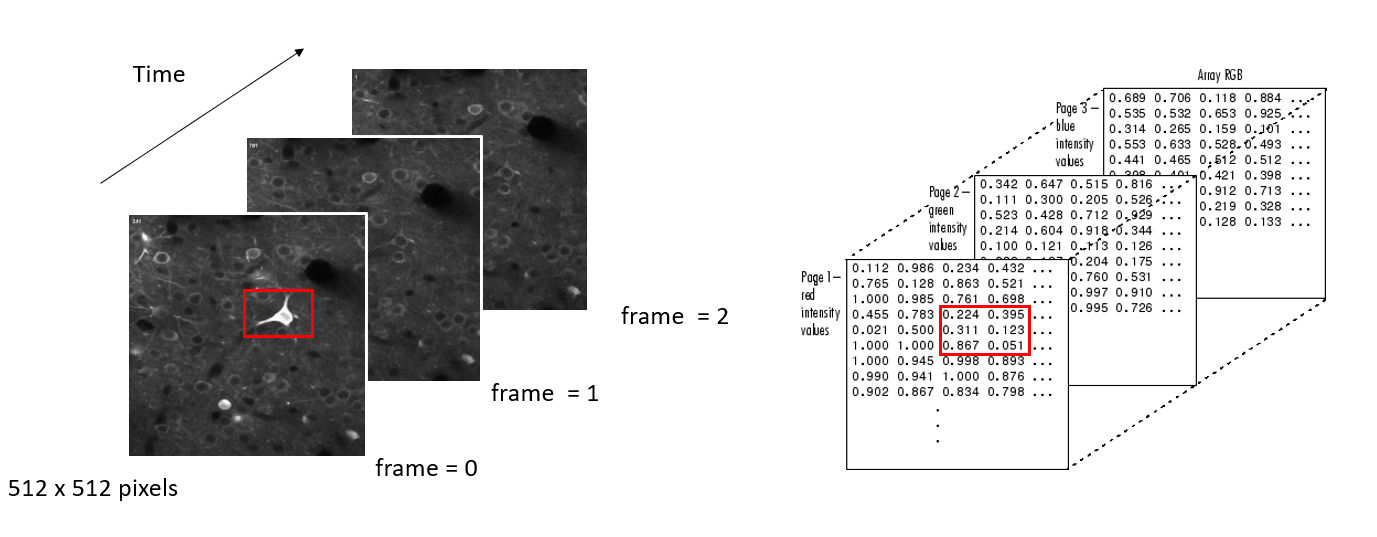

However, from such a matrix of numbers, it is unclear which value belongs to which neuron. By eye, this may be clear, but we want to employ an automatic method to segment the data into cells and track their fluorescence over time. There are different software packages to do this, but the one most commonly used is [**suite2p**](https://github.com/MouseLand/suite2p) (Pachitariu et al., *BioRxiv*, 2016). Suite2p performs a couple of steps:

1.  **Registration**: It starts by aligning each frame in the video so that each pixel in each frame represents the same anatomical location. This accounts for movement of the animal during imaging.
2. **ROI detection**: Next, it uses spatiotemporal information and patterns to identify ROIs (regions of interest) that belong to a single neuron. It finds the shape and size of each cell.
3. **Quality control**: By visualising the results and constructing various metrics, the researcher can check whether the algorithm did a good job and correct it if needed.
4. **Activity extraction**: Once the ROIs are defined and checked, suite2p will extract the fluorescence trace of each cell. It can also perform a *deconvolution*, which essentially cleans up the data with the goal of leaving only calcium transients corresponding to spiking activity.

We will use a two\-photon calcium imaging data set to quantify orientation tuning of visual cortex neurons.

#### **Orientation tuning**

Neurons in primary visual cortex are tuned to different orientations, which becomes particularly evident when presenting *drifting gratings*, which are essentially moving bars with a particular orientation (angle). We can quantify to which orientations neurons show the most activity, which allows to quantify what angle a neuron "prefers" (is tuned to) for each cell.

#### Case study

In this case study, we will look at two\-photon fluorescence data collected from an awake mouse viewing moving gratings with different orientations. There are 8 different orientations (0, 22.5, 45, 67.5, 90, 112.5, 135, and 157.5 degrees). Each orientation was repeated 10 times (but all in random order).


The data was collected from primary visual cortex from neurons expressing GCaMP6, which was virally injected.


Let's start by loading the data, which is a variable called <samp>ses</samp>. <samp>ses</samp> is a struct with all the information and variables we need.


In [ ]:
data_folder =  r"C:\Users\brouw\Documents\PhD\Teaching\PAND\Non_git_folder\Imaging_Analysis"
session = np.load(os.path.join(data_folder, '2P.npy'), allow_pickle=True).item()
print(f"Available keys in session: {list(session.keys())}")

Some relevant fields in our structure are:

-  `session['structStim']` contains information about the stimuli (notably the subfield `Orientation` with the orientation of each stimulus shown in order and `FrameOn`, which contains the frame number when each stimulus was presented).
-  `session['neuron']` contains information about the neurons (it is a list of neurons and their properties), notably `dFoF` which is the $\Delta F/F$ for each neuron over time.

Let's take a look at the subfields.

In [ ]:
# Feel free to explore the (sub)fields of session
print(session['neuron'][136].keys())


Now, we call the function `get_neuron_response()` which yields a matrix of neural responses (average fluorescence values). Print the dimensions of this matrix and explain what each dimension means. 

In [ ]:
def get_neuron_response(ses, neurons=None, stims=None):
    start_frames = ses['structStim']['FrameOff']
    stop_frames = np.concatenate((ses['structStim']['FrameOn'][1:], [len(ses['neuron'][0]['dFoF'])]))

    if stims is None:
        stims = np.arange(1, len(ses['structStim']['FrameOff'])+1)
    n_repetitions = np.size(stims)

    if neurons is None:
        neurons = np.arange(1, len(ses['neuron'])+1)
    n_neurons = np.size(neurons)
    
    response = np.empty((n_neurons, n_repetitions))

    for i_stim in range(n_repetitions):
        for i_neuron in range(n_neurons):
            dbl_baseline = 0
            response[i_neuron, i_stim] = np.mean(ses['neuron'][i_neuron]['dFoF'][start_frames[i_stim]:stop_frames[i_stim]]) - dbl_baseline

    return response
    
responses = get_neuron_response(session)
print(responses.shape)



*Your answer here*


#### Computing the tuning of each neuron to the orientations


We have our matrix of responses `responses`, but if we want to compute the tuning of each neuron to each orientation (the **tuning curve**), this is not ideal. `responses` stores the response per trial, but we would like to get the response per orientation.

To resolve this, please create a function `get_tuning_curves()` which takes `session` as input and outputs a variable called `tuning`. This function should do the following:

1.  Call `getNeuronResponse()` to get the `responses` matrix;
2.  Find the orientation that was prsented for each trial for this you can use session['structStim']['Orientation']
3.  Reshape the data so it is now 10 x 8 x 137 (trials x orientations x neurons) you can do this with a loop or with the reshape function
4.  Ensure that the function returns this resorted response data


To achieve the second step in an efficient way, we would encourage you to try and find a solution using the `session['structStim']['Orientation']` field and the `np.argsort()` function. However, if you cannot figure out how to do this, you could also get the solution by using a for loop.

The size of `tuning` should be (repetitions by orientations by neurons), so 10 by 8 by 137. We have included a call to verify this.

In [ ]:
# Complete the function
def get_tuning_curves(session):
 
    # Sort the orientations in ascending order and get the sorting indices,
    # so that we can sort the neural responses in the same way.

    # Sort the neural responses using our sorting indices from the orientation.
    # Do this along the correct dimension (namely, trials).
    # You can also see this from the sizes of the dimensions.

    # Make sure the sorted_responses are 10 x 8 x 137, so transpose, and then reshape into
    # the desired size.
    return sorted_responses

tuning = get_tuning_curves(session)



#### Computing the orientation selectivity index
Now that we have obtained an easier matrix to work with to compute our **orientation tuning**, let's do so. The extent to which a neuron has selective responses to a particular orientation can be quantified using the **orientation selectivity index** (OSI), defined as


$$\textrm{OSI}=\frac{A_{\textrm{pref}} -A_{\textrm{orth}} }{A_{\textrm{pref}} +A_{_{\textrm{orth}} } },$$

where $A_{\textrm{pref}}$ is the activity of the neuron upon presentation of its preferred orientation and $A_{\textrm{orth}}$ is the activity of that same neuron when presented with the orientation orthogonal to its preferred orientation. The orthogonal orientation is the preferred orientation plus 90 degrees, $A_{\textrm{orth}} =A_{\textrm{pref}} +90$ .


What we want to do is to calculate for each neuron the average fluorescence response over reptitions, so that we get the mean response to every orientation for each neuron. For every cell, we can then derive the preferred and thus orthogonal orientation and their response towards both. This gives us all the ingredients we need to calculate the OSI.


Please write a function `calc_ori_tuning()` that outputs the OSI for each neuron (i.e., a 1x137 vector) and the preferred orientation of each neuron (i.e., a 1x137 vector). In steps, the function should:

1.  Calculate the mean response over trials, yielding an 8x137 matrix (make sure you understand why).
2. Get the preferred orientation for each neuron and its activity level to that preferred response, which would be your $A_{\textrm{pref}}$ (hint: use `np.max()` and/or `np.argmax()`).
3. Find the orthogonal orientation (remember, $A_{\textrm{orth}} =A_{\textrm{pref}} +90$ ) and the fluorescence level to that response (which would be $A_{\textrm{orth}}$ ). Think of how 
4. Calculate the OSI for every neuron and store the preferred orientations per neuron.

This function may be a bit more complex in terms of steps required to get to the correct quantities, so take your time to think about the steps you would take.


In [ ]:
def calc_ori_tuning(tuning):
    orientations = np.array([0, 22.5, 45, 67.5, 90, 112.5, 135, 157.5])

    
    return osi, pref_ori

osi, pref_ori = calc_ori_tuning(tuning)


Now that we have our OSIs, let's plot them.

1.  Create a histogram of OSIs and make sure to label the axes.
2. Plot in the same histogram a line to display our criterion for orientation selectivity, which is OSI > 0.5. Based on this criterion, what percentage of neurons are sufficiently selective for orientation?
3. Plot the tuning curve of one of the neurons with an OSI > 0.5 does it show clear tuning? 
4. Plot another histogram of preferred orientations for the neurons that satisfy our selectivity criterion (OSI > 0.5). Are all orientations equally represented in the population?

In [ ]:
orientations = np.array([0, 22.5, 45, 67.5, 90, 112.5, 135, 157.5])
# Histogram of OSIs

# Histogram of preferred orientations


#### Visualising the fluorescence traces

The session file also contains $\Delta F/F$ traces for each neuron, namely in `session['neuron'][i]['dFoF']` for the *i*\-th neuron.


In three subplots, plot the fluorescence traces of three orientation\-selective neurons. Take the three neuron with the highest orientation selectivity. In the same plot, include the stimuli presentation times (e.g., using lines or stars). These frames can be found in `session['structStim']['FrameOn']`. Colour the stimulus time indicators by the orientation of the stimulus that was presented.

Make sure the plot includes the following:

-  Time on the *x*\-axis: Even though the `FrameOn` vector has frames as units, in your final plot, it would be great to show time on the *x*\-axis. Create your own time vector using `np.linspace()`, starting at 0. The data was collected at 25 Hz.
-  Labels on the axes.
-  A title showing which neuron is plotted and what its OSI is.
-  A legend to show which colour represents which orientation.

In these plots, can you see by eye some orientation selectivity for the plotted neurons?

#### Displaying the tuning curves
Finally, we can visualise how tuned a neuron is to each orientation by plotting its **tuning curve**. A tuning curve plot generally has orientation on the *x*\-axis and an average response on the *y*\-axis (usually including an errorbar).

In three subplots, show the tuning curves for the same three neurons as before.

1.  Calculate the mean and standard error of the fluorescence response of each neuron to every orientation (i.e., start from `tuning`). Remember the standard error is $\textrm{SE}=\frac{\sigma }{N}$ , where $\sigma$ is the standard deviation and $N$ is the number of elements in our sample.
2. Plot the average response and SE against the orientations using `plt.errorbar()`.
3. Label the axes correctly (use `plt.xticks()` for this) and set the title of each subplot to the OSI of the corresponding cell.

#### Visualising the neurons in the imaging plane
As mentioned at the start, an advantage of two\-photon imaging is the increased spatial resolution. In fact, we get rather pretty images from two\-photon imaging. The advantage is that we see the cells in our *imaging plane*, and we can view how cells with certain properties are distributed over space.

As an example, we will locate the orientation\-selective neurons in this imaging plane. To do this, first download the `ImagingPlane.png` file from Canvas, which contains the image. Make note of the fact that the *x* and *y* position of each neuron in the imaging plane is contained in

```python
session['neuron'][i]['x']
```

```python
session['neuron'][i]['y']
```

To create this visualisation, follow the following steps:

1. Load the image file using `Image()`.
2. Plot the image using `plt.imshow()`.
3. Plot a coloured star at the locations of each orientation\-selective neuron. Make sure the colour of the stars corresponds to the preferred orientation of each neuron.

Is there anything we might conclude about the spatial organisation of orientation\-selective neurons in mouse primary visual cortex?

In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import os

img_folder = r"C:\Users\brouw\Documents\PhD\Teaching\PAND\Non_git_folder\Imaging_Analysis"
file_path = os.path.join(img_folder, 'ImagingPlane.png')

img = np.asarray(Image.open(file_path))



#### Bonus: Tuning curves for somatostatin\-expressing interneurons
Our data also contains the activity of somatostatin (SOM) expressing interneurons, which are tagged with a red fluorescent protein. These interneurons are important in regulating the balance between excitation and inhibition and can influence timing and synchronisation of neuronal activity.

Let's investigate whether these neurons also show orientation selectivity. The field `session['SOM']` contains the activity of six interneurons. Following the same steps as before, create a figure with six subplots that shows the tuning curve for each of them.

To get a compatible structure for the call to `get_tuning_curves()`, we recommend copying the original `session` and assigning `session['SOM']` to the `neuron` field in this new `ses_som` dictionary.

In [ ]:
from copy import deepcopy

ses_som = deepcopy(session)
ses_som['neuron'] = session['SOM']

# Your code here